# E3 – Modelado Predictivo de Riesgo Crediticio con Árboles de Decisión

**Autor:** Renato Acosta,
Bruno Aldana,
Alanis Figueroa,
Benjamin Jara.


**Fecha de Creación:** Noviembre de 2026

**Versión:** 1.1

---

## Descripción

Una institución financiera recibe solicitudes de **préstamos hipotecarios** y necesita estimar el riesgo de incumplimiento (`Riesgo_Impago`: 1 = impago / default, 0 = cumple sus pagos).

Este notebook implementa el pipeline completo de la evaluación E3:

| Fase | Contenido |
|---|---|
| 1 | Diagnóstico y calidad de datos (EDA) |
| 2 | Limpieza y tratamiento mediante `Pipeline` + `ColumnTransformer` de Scikit-Learn |
| 3 | División estratificada, modelo base y modelo optimizado (`DecisionTreeClassifier`, >= 4 hiperparámetros) |
| 4 | Dos métricas sobre el conjunto de prueba (Recall y Precision de la clase impago), comparación contra estrategias triviales e interpretación de matrices de confusión en términos financieros |

**Costos de negocio (estudios preliminares):**
- **Falso Negativo (FN)**: se otorga un crédito que termina en impago → **$1.500.000**
- **Falso Positivo (FP)**: se deniega un crédito que habría sido pagado → **$200.000** (costo de oportunidad por intereses no ganados)

Semilla utilizada en todo el notebook: `random_state = 29`.

---

## Requisitos de Software

Python 3.12 y las bibliotecas: pandas, numpy, matplotlib, seaborn y scikit-learn (>= 1.3).

In [29]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             fbeta_score, make_scorer, precision_score, accuracy_score,
                             classification_report)

RANDOM_STATE = 29
COSTO_FN = 1_500_000   # credito otorgado que termina en impago
COSTO_FP = 200_000     # credito viable denegado (costo de oportunidad)

sns.set_theme(style="whitegrid")

# Fase 1 – Diagnóstico y Calidad de Datos (EDA)




## 1.1 Carga del dataset

In [30]:
# Se intenta primero un archivo local (misma carpeta del notebook) y, si no existe, la copia del repositorio.
URL_CSV = "https://raw.githubusercontent.com/alanis1328/Inteligencia-Artificial-620454/main/E3%20-%20Classifier%20/riesgo_crediticio.csv"
try:
    df = pd.read_csv("riesgo_crediticio.csv", index_col=0)
    print("Datos cargados desde archivo local.")
except FileNotFoundError:
    df = pd.read_csv(URL_CSV, index_col=0)
    print("Datos cargados desde el repositorio de GitHub.")
print("Dimensiones:", df.shape)
df.head()

Datos cargados desde el repositorio de GitHub.
Dimensiones: (25000, 5)


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,39785.55,85246.38,694.0,70.00,0
1,69773.95,244260.00,622.0,10.65,0
2,127770.68,209310.35,780.0,42.70,0
3,16799.80,213059.98,741.0,48.04,0
4,70229.83,219523.13,714.0,25.58,0


## 1.2 Estructura y tipos de datos

In [31]:
df.info()
print()


<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.1 MB



##1.3 Valores nulos

In [32]:
print("--- Valores nulos por columna ---")
print(df.isna().sum())
print("\n--- Filas duplicadas ---")
print(df.duplicated().sum())

--- Valores nulos por columna ---
Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64

--- Filas duplicadas ---
0


In [33]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.44,29804.90,7832.12,35051.32,49234.68,68923.52,348135.55
Monto_Prestamo,25000.0,220162.89,60059.30,50000.00,179438.08,220241.47,261003.36,451784.21
Puntaje_Credito,25000.0,680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,25000.0,24.03,13.62,5.00,13.79,21.45,31.38,70.00
Riesgo_Impago,25000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00


**Hallazgos iniciales:** el dataset tiene 25.000 registros y 5 columnas numéricas, sin valores nulos ni filas duplicadas, y con los tipos de dato esperados (4 variables continuas `float64` y el target binario `int64`).

Lectura de `describe()`: todos los mínimos y máximos caen dentro de rangos plausibles para una cartera hipotecaria: ingreso entre ≈ \$7.800 y ≈ \$348.000 anuales (media > mediana, lo que anticipa asimetría a la derecha), préstamo entre \$50.000 y ≈ \$452.000, puntaje entre 457 y 850 (dentro de la escala 300–850) y DTI entre 5 % y 70 %. El promedio del target (≈ 0,07) ya adelanta el desbalance que se analiza en 1.5.

## 1.4 Inconsistencias lógicas y rangos de negocio

In [34]:
features = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]

reglas = pd.DataFrame({
    "Ingreso_Anual <= 0":              [(df["Ingreso_Anual"] <= 0).sum()],
    "Monto_Prestamo <= 0":             [(df["Monto_Prestamo"] <= 0).sum()],
    "Puntaje fuera de [300, 850]":     [((df["Puntaje_Credito"] < 300) | (df["Puntaje_Credito"] > 850)).sum()],
    "Relacion Deuda-Ingreso <= 0%":    [(df["Relacion_Deuda_Ingreso"] <= 0).sum()],
    "Relacion Deuda-Ingreso > 100%":   [(df["Relacion_Deuda_Ingreso"] > 100).sum()],
    "Target fuera de {0,1}":           [(~df["Riesgo_Impago"].isin([0, 1])).sum()],
}).T.rename(columns={0: "N° de registros inconsistentes"})
display(reglas)

print("--- Valores acumulados en los limites (posible censura / tope del dato) ---")
print("Puntaje_Credito == 850 :", (df["Puntaje_Credito"] == 850).sum())
print("Relacion_Deuda_Ingreso == 70 (max):", (df["Relacion_Deuda_Ingreso"] == df["Relacion_Deuda_Ingreso"].max()).sum())
print("Monto_Prestamo == 50.000 (min):", (df["Monto_Prestamo"] == df["Monto_Prestamo"].min()).sum())

,N° de registros inconsistentes
Ingreso_Anual <= 0,0
Monto_Prestamo <= 0,0
"Puntaje fuera de [300, 850]",0
Relacion Deuda-Ingreso <= 0%,0
Relacion Deuda-Ingreso > 100%,0
"Target fuera de {0,1}",0


--- Valores acumulados en los limites (posible censura / tope del dato) ---
Puntaje_Credito == 850 : 49
Relacion_Deuda_Ingreso == 70 (max): 196
Monto_Prestamo == 50.000 (min): 53


**Interpretación:** no existen inconsistencias lógicas (ingresos/montos <= 0, puntajes fuera de la escala 300–850, DTI imposibles).

Sí se observa acumulación de registros en los extremos de tres variables (puntaje = 850, DTI = 70 y monto = \$50.000). Esto es compatible con **topes (censura) en la captura del dato o con límites de política de la institución**, pero con la información disponible es una **hipótesis, no un hecho verificado**; conviene confirmarla con el área de negocio. En ningún caso son valores imposibles, por lo que se conservan.

## 1.5 Distribución de la variable objetivo (desbalance)

               Clientes  Porcentaje (%)
Riesgo_Impago                          
0                 23211           92.84
1                  1789            7.16

Razon de desbalance (cumplidores : impagos) = 13.0 : 1


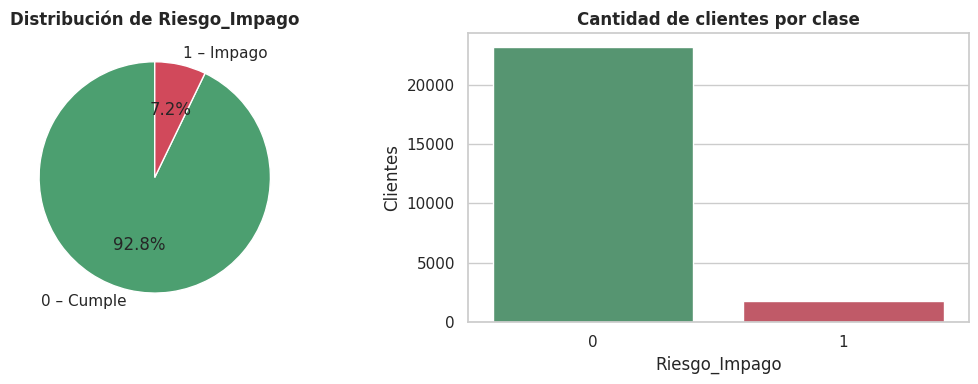

In [35]:
conteo = df["Riesgo_Impago"].value_counts().sort_index()
porc = df["Riesgo_Impago"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"Clientes": conteo, "Porcentaje (%)": porc.round(2)}))
print(f"\nRazon de desbalance (cumplidores : impagos) = {conteo[0]/conteo[1]:.1f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(conteo, labels=["0 – Cumple", "1 – Impago"], autopct="%1.1f%%",
          colors=["#4C9F70", "#D1495B"], startangle=90)
ax[0].set_title("Distribución de Riesgo_Impago", fontweight="bold")
sns.barplot(x=conteo.index, y=conteo.values, palette=["#4C9F70", "#D1495B"], ax=ax[1])
ax[1].set_title("Cantidad de clientes por clase", fontweight="bold")
ax[1].set_xlabel("Riesgo_Impago"); ax[1].set_ylabel("Clientes")
plt.tight_layout(); plt.show()

**Interpretación:** el target está **fuertemente desbalanceado**: solo ~7,2 % de los clientes cae en impago (≈ 13 cumplidores por cada impago). Esto condiciona todo el análisis: un modelo que prediga siempre "cumple" tendría ~93 % de *accuracy* y sería inútil para el banco, por lo que la métrica `accuracy` **no** es adecuada y debemos usar métricas centradas en la clase minoritaria.

## 1.6 Distribución de variables y outliers

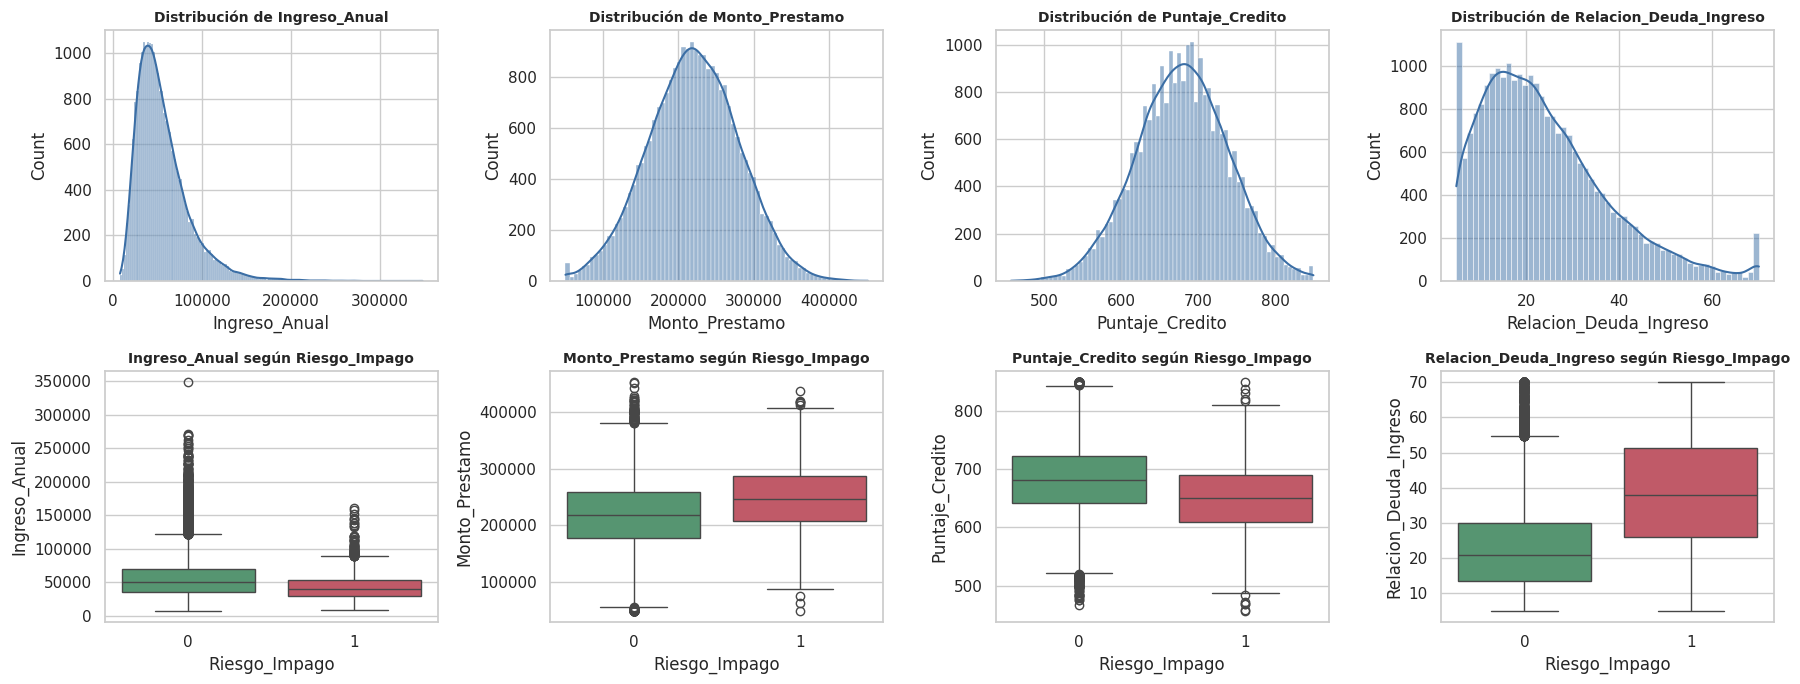

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="#3B6EA5")
    axes[0, i].set_title(f"Distribución de {col}", fontsize=10, fontweight="bold")
    sns.boxplot(x="Riesgo_Impago", y=col, data=df, palette=["#4C9F70", "#D1495B"], ax=axes[1, i])
    axes[1, i].set_title(f"{col} según Riesgo_Impago", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

In [37]:
# Cuantificacion de outliers con el criterio del rango intercuartilico (IQR)
filas = []
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    filas.append([col, round(lo, 2), round(hi, 2), n_out, round(100 * n_out / len(df), 2)])
pd.DataFrame(filas, columns=["Variable", "Límite inf.", "Límite sup.", "N° outliers", "% outliers"])

,Variable,Límite inf.,Límite sup.,N° outliers,% outliers
0,Ingreso_Anual,-15756.99,119731.82,976,3.90
1,Monto_Prestamo,57090.15,383351.29,157,0.63
2,Puntaje_Credito,518.50,842.50,167,0.67
3,Relacion_Deuda_Ingreso,-12.60,57.77,663,2.65


**Interpretación:** `Ingreso_Anual` presenta una distribución asimétrica a la derecha con un número relevante de valores atípicos altos (personas de altos ingresos, plausibles en el mundo real); `Monto_Prestamo` y `Relacion_Deuda_Ingreso` también muestran algunos extremos.

Nota sobre la tabla: los **límites inferiores negativos** de `Ingreso_Anual` y `Relacion_Deuda_Ingreso` son solo un artefacto matemático de la fórmula de Tukey (Q1 − 1,5·IQR); como los mínimos reales son \$7.832 y 5 %, **no existen outliers por abajo** y todos los atípicos de esas variables son altos. Estos valores **no son errores**, por lo que no se eliminan; el `RobustScaler` (mediana e IQR) evita que distorsionen el escalado.

A nivel de negocio, los boxplots por clase muestran que los clientes en impago tienden a tener **menor puntaje de crédito, mayor DTI y menor ingreso**.

## 1.7 Relación de las variables con el target

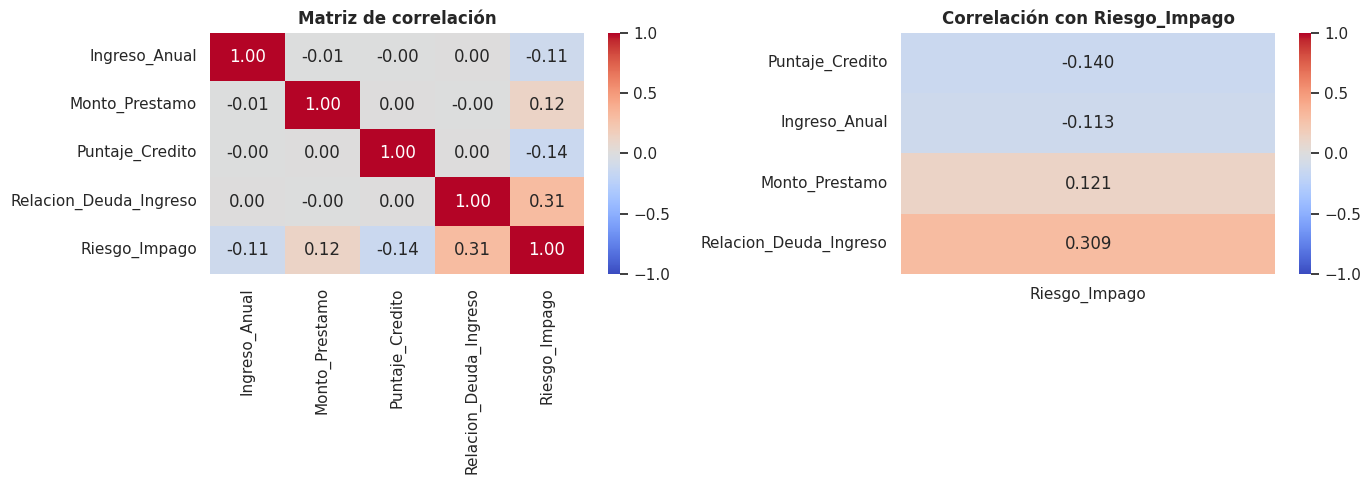

               Ingreso_Anual  Monto_Prestamo  Puntaje_Credito  \
Riesgo_Impago                                                   
0                   56757.46       218140.82           682.36   
1                   43719.24       246397.83           649.85   

               Relacion_Deuda_Ingreso  
Riesgo_Impago                          
0                               22.86  
1                               39.18  


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de correlación", fontweight="bold")

tc = corr[["Riesgo_Impago"]].drop("Riesgo_Impago").sort_values("Riesgo_Impago")
sns.heatmap(tc, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Correlación con Riesgo_Impago", fontweight="bold")
plt.tight_layout(); plt.show()

print(df.groupby("Riesgo_Impago")[features].mean().round(2))

## 1.8 Resumen de calidad de datos

| Aspecto | Resultado | Acción |
|---|---|---|
| Nulos | 0 | Se incluye imputación por mediana en el pipeline como medida preventiva (datos futuros) |
| Duplicados | 0 | Ninguna |
| Tipos de datos | Correctos (numéricos) | Ninguna |
| Inconsistencias lógicas | 0 | Se deja en el pipeline una regla de validación que convierte valores imposibles en nulos para imputarlos |
| Outliers | Presentes sobre todo en ingreso (solo por arriba; los límites inferiores negativos son artefacto de la fórmula IQR) | Se conservan; `RobustScaler` |
| Topes en extremos (850, DTI = 70, monto = 50.000) | Presentes | Posible censura/política de la institución (hipótesis por confirmar con negocio); se conservan |
| Desbalance del target | ≈ 7,2 % de impagos | Métricas sobre clase minoritaria, división estratificada, `class_weight` y validación cruzada estratificada |

# Fase 2 – Limpieza y Tratamiento de Datos (Pipeline)



Se diseña un `Pipeline` de Scikit-Learn con dos etapas de preprocesamiento. Todas las transformaciones se **ajustan solo con el conjunto de entrenamiento** y se aplican luego a prueba, evitando *data leakage*:

1. **`limpieza_logica`** (`FunctionTransformer`): marca como nulos los valores lógicamente imposibles (montos/ingresos <= 0, puntaje fuera de 300–850, DTI fuera de (0, 100]).
2. **`preprocesamiento`** (`ColumnTransformer`): sobre las variables numéricas aplica `SimpleImputer(median)` (robusto a outliers) y `RobustScaler`.

Con los datos actuales (0 nulos, 0 inconsistencias) las etapas de validación e imputación **no modifican ningún valor**; se mantienen como **protección preventiva** para datos nuevos que lleguen a producción con errores de captura. Por eso están dentro del pipeline y no aplicadas "a mano" sobre el dataset.

### 2.1 Justificación Técnica






#### 1. ¿Por qué se imputó con la Mediana (`SimpleImputer(strategy="median")`)?
* **Representatividad ante asimetría:** La variable `Ingreso_Anual` presenta una asimetría positiva con valores altos de hasta \$348.000. En distribuciones sesgadas, la media aritmética se desplaza artificialmente hacia los valores altos.
* **El valor más típico:** La mediana (percentil 50) divide la muestra exactamente a la mitad. Si un dato futuro viene nulo o resulta inválido tras la validación lógica, rellenarlo con la mediana garantiza asignarle el valor de un **cliente típico**, sin inflar falsamente su capacidad financiera con un promedio alterado por los clientes más ricos.

#### 2. ¿Por qué se utilizó el criterio IQR (Rango Intercuartílico)?
* **Fórmula no paramétrica:** El rango intercuartílico ($\text{IQR} = Q_3 - Q_1$) mide la dispersión del **50% central** de la población.
* **Independencia de la distribución normal:** Criterios como la regla empírica o Z-score asumen que los datos siguen una campana de Gauss simétrica. Dado que las variables financieras (`Ingreso_Anual` y `Relacion_Deuda_Ingreso`) no son normales, el criterio de Tukey basado en cuartiles es el método estadístico adecuado para delimitar valores atípicos sin imponer supuestos teóricos que no se cumplen en los datos reales.

#### 3. ¿Por qué se incluyó `RobustScaler` si el modelo es un árbol de decisión?
* **Aclaración honesta:** los árboles de decisión parten los datos por umbrales sobre cada variable y, por lo tanto, **no necesitan escalado** (son prácticamente invariantes a transformaciones monótonas de las variables). En la sección 3.2 se verifica empíricamente que el escalado casi no altera las predicciones.
* **Por qué se deja igualmente:** (i) el pipeline queda **reutilizable** si el banco quiere comparar con modelos sensibles a la escala (regresión logística, KNN, SVM) sin rediseñar el preprocesamiento; (ii) no cuesta nada en rendimiento; (iii) se eligió `RobustScaler` en vez de `StandardScaler` para que los outliers legítimos de ingreso no distorsionen la escala:

$$\text{Valor Escalado} = \frac{x - \text{Mediana}}{\text{IQR}}$$

* **Costo:** la interpretación de los umbrales del árbol (sección 4.3) queda en unidades escaladas; la regla de negocio en unidades originales se obtiene invirtiendo la transformación si se requiere.


In [39]:
def validar_rangos(X):
    """Reemplaza por NaN los valores logicamente imposibles (se imputaran despues)."""
    X = X.copy()
    X.loc[X["Ingreso_Anual"] <= 0, "Ingreso_Anual"] = np.nan
    X.loc[X["Monto_Prestamo"] <= 0, "Monto_Prestamo"] = np.nan
    X.loc[(X["Puntaje_Credito"] < 300) | (X["Puntaje_Credito"] > 850), "Puntaje_Credito"] = np.nan
    X.loc[(X["Relacion_Deuda_Ingreso"] <= 0) | (X["Relacion_Deuda_Ingreso"] > 100), "Relacion_Deuda_Ingreso"] = np.nan
    return X

def crear_pipeline(modelo, escalar=True):
    """Pipeline completo: limpieza logica -> imputacion (+ escalado) -> modelo.
    Cada llamada construye transformadores NUEVOS, de modo que ningun objeto
    (ni su estado ajustado) se comparte entre el modelo base y el optimizado."""
    pasos_numericos = [("imputador", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_numericos.append(("escalador", RobustScaler()))
    return Pipeline(steps=[
        ("limpieza_logica", FunctionTransformer(validar_rangos, feature_names_out="one-to-one")),
        ("preprocesamiento", ColumnTransformer(
            transformers=[("num", Pipeline(steps=pasos_numericos), features)],
            remainder="drop")),
        ("modelo", modelo),
    ])

# Visualizacion del pipeline
crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))

Pipeline(steps=[('limpieza_logica',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<function validar_rangos at 0x7b0fefcd2980>)),
                ('preprocesamiento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputador',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalador',
                                                                   RobustScaler())]),
                                                  ['Ingreso_Anual',
                                                   'Monto_Prestamo',
                                                   'Puntaje_Credito',
                                                   'Relacion_Deuda_Ingreso'])])),
                ('modelo', DecisionTreeClassifier(random_state=29))])

# Fase 3 – Construcción del Modelo


## 3.1 División en entrenamiento y prueba (estratificada)



Se usa `stratify=y` para conservar la proporción de impagos (~7,2 %) tanto en entrenamiento como en prueba.

In [40]:
X = df[features]
y = df["Riesgo_Impago"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\n% de impagos en cada conjunto:")
print(f"  Original : {y.mean()*100:.2f}%")
print(f"  Train    : {y_train.mean()*100:.2f}%")
print(f"  Test     : {y_test.mean()*100:.2f}%")

Train: (20000, 4) | Test: (5000, 4)

% de impagos en cada conjunto:
  Original : 7.16%
  Train    : 7.16%
  Test     : 7.16%


## 3.2 Modelo base (línea base)

`DecisionTreeClassifier` con hiperparámetros **por defecto** (solo se fija `random_state=29`). Sin restricción de profundidad, el árbol tenderá a sobreajustar los datos de entrenamiento.

In [41]:
modelo_base = crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
modelo_base.fit(X_train, y_train)

arbol_base = modelo_base.named_steps["modelo"]
print("Profundidad del árbol base :", arbol_base.get_depth())
print("N° de hojas del árbol base :", arbol_base.get_n_leaves())
print(f"Recall (impago) en TRAIN : {recall_score(y_train, modelo_base.predict(X_train)):.3f}")
print(f"Recall (impago) en TEST  : {recall_score(y_test, modelo_base.predict(X_test)):.3f}")

Profundidad del árbol base : 31
N° de hojas del árbol base : 1623
Recall (impago) en TRAIN : 1.000
Recall (impago) en TEST  : 0.316


**Verificación del escalado:** se entrena el mismo árbol por defecto **sin** `RobustScaler` y se comparan las predicciones sobre el conjunto de prueba.

In [42]:
base_sin_escala = crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), escalar=False).fit(X_train, y_train)
n_dif = int((modelo_base.predict(X_test) != base_sin_escala.predict(X_test)).sum())
print(f"Predicciones distintas con vs. sin escalado: {n_dif} de {len(X_test)} ({n_dif/len(X_test)*100:.2f} %)")
print(f"Recall (impago) con escalado: {recall_score(y_test, modelo_base.predict(X_test)):.4f} | sin escalado: {recall_score(y_test, base_sin_escala.predict(X_test)):.4f}")

Predicciones distintas con vs. sin escalado: 4 de 5000 (0.08 %)
Recall (impago) con escalado: 0.3156 | sin escalado: 0.3156


Las diferencias son mínimas y se deben a empates en los umbrales por redondeo de punto flotante: confirma que, para un árbol, el escalado es irrelevante; se mantiene solo por reutilización del pipeline (ver 2.1).



## 3.3 Modelo optimizado (búsqueda de hiperparámetros)



In [43]:
scorer_f2 = make_scorer(fbeta_score, beta=2, pos_label=1)
param_grid = {
    "modelo__criterion":        ["gini", "entropy"],
    "modelo__max_depth":        [5, 8, 12, None],
    "modelo__min_samples_leaf": [20, 50, 100, 200],
    "modelo__max_features":     [None, "sqrt"],
    "modelo__class_weight":     [None, "balanced", {0: 1, 1: COSTO_FN / COSTO_FP}],
    "modelo__ccp_alpha":        [0.0, 0.0005, 0.001, 0.002],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busqueda = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid=param_grid,
    scoring=scorer_f2,
    cv=cv,
    n_jobs=-1,
    refit=True,
)
n_comb = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Combinaciones: {n_comb} x {cv.get_n_splits()} folds = {n_comb * cv.get_n_splits()} ajustes (puede tardar unos minutos)")
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:")
for k, v in busqueda.best_params_.items():
    print(f"  {k.replace('modelo__', ''):<18}: {v}")
print(f"\nMejor F2 (validación cruzada): {busqueda.best_score_:.4f}")

modelo_opt = busqueda.best_estimator_
arbol_opt = modelo_opt.named_steps["modelo"]
print("Profundidad del árbol optimizado:", arbol_opt.get_depth(), "| Hojas:", arbol_opt.get_n_leaves())

Combinaciones: 768 x 5 folds = 3840 ajustes (puede tardar unos minutos)
Mejores hiperparámetros:
  ccp_alpha         : 0.0
  class_weight      : {0: 1, 1: 7.5}
  criterion         : entropy
  max_depth         : 12
  max_features      : None
  min_samples_leaf  : 100

Mejor F2 (validación cruzada): 0.4716
Profundidad del árbol optimizado: 12 | Hojas: 128


In [44]:
# Top 5 combinaciones segun la validacion cruzada
res = pd.DataFrame(busqueda.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
res[cols].sort_values("mean_test_score", ascending=False).head(5).round(4)

,param_modelo__ccp_alpha,param_modelo__class_weight,param_modelo__criterion,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,mean_test_score,std_test_score
178,0.0,"{0: 1, 1: 7.5}",entropy,12,None,100,0.4716,0.0264
110,0.0,balanced,entropy,8,sqrt,100,0.4715,0.0135
138,0.0,"{0: 1, 1: 7.5}",gini,8,None,100,0.4709,0.0320
186,0.0,"{0: 1, 1: 7.5}",entropy,None,None,100,0.4708,0.0252
170,0.0,"{0: 1, 1: 7.5}",entropy,8,None,100,0.4707,0.0231


In [45]:
# Sensibilidad: mejor F2 de validacion cruzada alcanzado por cada valor de cada hiperparametro
res = pd.DataFrame(busqueda.cv_results_)
for p in param_grid:
    col = "param_" + p
    tab = res.groupby(res[col].astype(str))["mean_test_score"].max().round(4)
    print(f"{p.replace('modelo__', ''):<18}", " | ".join(f"{k}: {v}" for k, v in tab.items()))

# Revision de bordes de la grilla para los hiperparametros ordenados
print("\nPosicion del valor elegido dentro de la grilla (primero/ultimo = borde):")
for p in ["modelo__max_depth", "modelo__min_samples_leaf", "modelo__ccp_alpha"]:
    vals = param_grid[p]; best = busqueda.best_params_[p]
    pos = vals.index(best)
    if p == "modelo__ccp_alpha" and best == 0.0:
        estado = "limite natural: 0 = sin poda, no hay truncamiento"
    else:
        estado = "BORDE" if pos in (0, len(vals) - 1) else "interior"
    print(f"  {p.replace('modelo__', ''):<18}: {best} (posicion {pos + 1} de {len(vals)}, {estado})")

criterion          entropy: 0.4716 | gini: 0.4709
max_depth          12: 0.4716 | 5: 0.4618 | 8: 0.4715 | None: 0.4708
min_samples_leaf   100: 0.4716 | 20: 0.4656 | 200: 0.4673 | 50: 0.4649
max_features       None: 0.4716 | sqrt: 0.4715
class_weight       None: 0.2182 | balanced: 0.4715 | {0: 1, 1: 7.5}: 0.4716
ccp_alpha          0.0: 0.4716 | 0.0005: 0.4691 | 0.001: 0.4661 | 0.002: 0.4604

Posicion del valor elegido dentro de la grilla (primero/ultimo = borde):
  max_depth         : 12 (posicion 3 de 4, interior)
  min_samples_leaf  : 100 (posicion 3 de 4, interior)
  ccp_alpha         : 0.0 (posicion 1 de 4, limite natural: 0 = sin poda, no hay truncamiento)


**Lectura:** la tabla muestra que cada hiperparámetro influye en el desempeño (p. ej., `ccp_alpha` mayor o `max_depth = 5` empeoran el F2 de validación cruzada) y el bloque de bordes verifica que el óptimo **no quedó truncado** por el rango explorado: `max_depth` y `min_samples_leaf` quedaron en el interior de la grilla, y `ccp_alpha = 0` es el límite natural (sin poda), no un recorte arbitrario. Además, las mejores combinaciones del *top 5* son casi idénticas (diferencias de milésimas, muy inferiores a la desviación estándar entre folds): hay una **meseta**, por lo que ampliar la grilla no aportaría mejoras materiales.

# Fase 4 – Evaluación e Interpretación de Métricas (conjunto de prueba)



## 4.1 Selección y justificación de las dos métricas

Con ~7 % de impagos, **`accuracy` es engañosa** (aprobar a todos los clientes ya da ~93 %). Se eligen **dos métricas complementarias, centradas en la clase de impago (positiva)** y alineadas con la asimetría de costos del banco:

1. **Recall de la clase impago (sensibilidad)** = VP / (VP + FN). Responde: *de los clientes que realmente caerán en impago, ¿qué porcentaje detecta el modelo?* Es la métrica directamente ligada al error más caro (FN = \$1.500.000 por crédito malo otorgado).
2. **Precision de la clase impago** = VP / (VP + FP). Responde: *de los clientes que el modelo marca como riesgosos, ¿qué porcentaje realmente caería en impago?* Es la métrica ligada al error más barato (FP = \$200.000 por crédito bueno rechazado) y es el **contrapeso necesario del recall**: sin ella, un modelo que rechaza a todos tendría recall = 1 y parecería perfecto.

Las dos métricas miden **errores distintos** (FN y FP) y juntas muestran el intercambio que el banco debe gestionar. Dado que un FN cuesta 7,5 veces más que un FP (1.500.000 / 200.000), se acepta sacrificar precision para ganar recall.

**Criterio de búsqueda de hiperparámetros:** para *elegir* el modelo optimizado en validación cruzada se usa el **F2-score** (combina recall y precision pesando más al recall), porque resume en un solo número el equilibrio deseado y es coherente con la razón de costos. El F2 es solo el criterio interno de búsqueda; **las métricas reportadas sobre prueba son Recall y Precision**. El **costo financiero total** y la *accuracy* se muestran únicamente como traducción a negocio y referencia, no como métricas de decisión.

In [46]:
def evaluar(nombre, modelo, X_t, y_t):
    y_pred = modelo.predict(X_t)
    tn, fp, fn, tp = confusion_matrix(y_t, y_pred).ravel()
    return {
        "Modelo": nombre,
        "Recall (impago)": recall_score(y_t, y_pred),
        "Precision (impago)": precision_score(y_t, y_pred),
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
        "Costo FN ($)": fn * COSTO_FN,
        "Costo FP ($)": fp * COSTO_FP,
        "Costo total ($)": fn * COSTO_FN + fp * COSTO_FP,
        "Accuracy [referencia]": accuracy_score(y_t, y_pred),
    }

resultados = pd.DataFrame([
    evaluar("Línea base", modelo_base, X_test, y_test),
    evaluar("Optimizado", modelo_opt, X_test, y_test),
]).set_index("Modelo")

metricas = resultados[["Recall (impago)", "Precision (impago)"]].round(4)
display(metricas)

costos = resultados[["VN", "FP", "FN", "VP", "Costo FN ($)", "Costo FP ($)", "Costo total ($)"]]
display(costos.style.format({"Costo FN ($)": "${:,.0f}", "Costo FP ($)": "${:,.0f}", "Costo total ($)": "${:,.0f}"}))

,Recall (impago),Precision (impago)
Modelo,,
Línea base,0.3156,0.2846
Optimizado,0.6564,0.2701


,VN,FP,FN,VP,Costo FN ($),Costo FP ($),Costo total ($)
Modelo,,,,,,,
Línea base,4358,284,245,113,"$367,500,000","$56,800,000","$424,300,000"
Optimizado,4007,635,123,235,"$184,500,000","$127,000,000","$311,500,000"


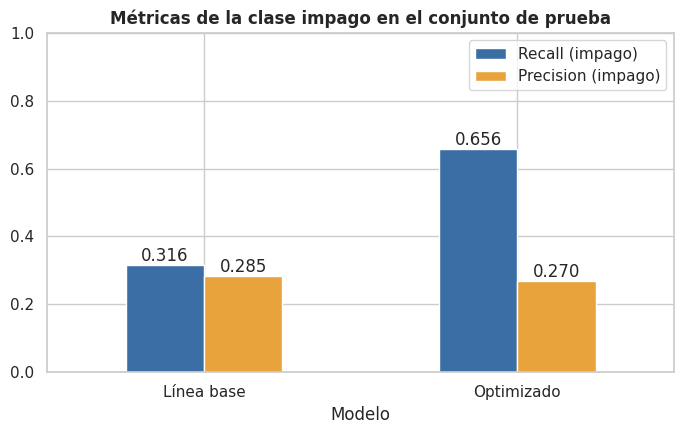

LÍNEA BASE
              precision    recall  f1-score   support

  Cumple (0)       0.95      0.94      0.94      4642
  Impago (1)       0.28      0.32      0.30       358

    accuracy                           0.89      5000
   macro avg       0.62      0.63      0.62      5000
weighted avg       0.90      0.89      0.90      5000

OPTIMIZADO
              precision    recall  f1-score   support

  Cumple (0)       0.97      0.86      0.91      4642
  Impago (1)       0.27      0.66      0.38       358

    accuracy                           0.85      5000
   macro avg       0.62      0.76      0.65      5000
weighted avg       0.92      0.85      0.88      5000



In [47]:
# Comparacion grafica de las dos metricas elegidas
ax = metricas.plot(kind="bar", figsize=(7, 4.5), color=["#3B6EA5", "#E8A33D"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
ax.set_ylim(0, 1)
ax.set_title("Métricas de la clase impago en el conjunto de prueba", fontweight="bold")
plt.tight_layout(); plt.show()

print("LÍNEA BASE");  print(classification_report(y_test, modelo_base.predict(X_test), target_names=["Cumple (0)", "Impago (1)"]))
print("OPTIMIZADO");  print(classification_report(y_test, modelo_opt.predict(X_test), target_names=["Cumple (0)", "Impago (1)"]))

### Referencia: ¿cuánto aporta cada modelo frente a decisiones triviales?

Para dimensionar el valor del modelo se compara contra dos políticas sin modelo: **aprobar a todos** (todo impago se vuelve FN) y **rechazar a todos** (todo cliente bueno se vuelve FP).

In [48]:
n0, n1 = int((y_test == 0).sum()), int((y_test == 1).sum())
bench = pd.DataFrame({
    "Aprobar a todos":  {"Recall (impago)": 0.0, "Precision (impago)": np.nan, "FP": 0,  "FN": n1, "Accuracy [referencia]": n0 / len(y_test)},
    "Rechazar a todos": {"Recall (impago)": 1.0, "Precision (impago)": n1 / len(y_test), "FP": n0, "FN": 0, "Accuracy [referencia]": n1 / len(y_test)},
}).T
for nom in ["Línea base", "Optimizado"]:
    r = resultados.loc[nom]
    bench.loc[nom] = {"Recall (impago)": r["Recall (impago)"], "Precision (impago)": r["Precision (impago)"],
                      "FP": r["FP"], "FN": r["FN"], "Accuracy [referencia]": r["Accuracy [referencia]"]}
bench["Costo total ($)"] = bench["FN"] * COSTO_FN + bench["FP"] * COSTO_FP
bench["Ahorro vs. aprobar a todos"] = 1 - bench["Costo total ($)"] / bench.loc["Aprobar a todos", "Costo total ($)"]
display(bench.style.format({"Recall (impago)": "{:.3f}", "Precision (impago)": "{:.3f}", "Accuracy [referencia]": "{:.3f}",
                            "FP": "{:,.0f}", "FN": "{:,.0f}", "Costo total ($)": "${:,.0f}", "Ahorro vs. aprobar a todos": "{:.1%}"}, na_rep="n/d"))

,Recall (impago),Precision (impago),FP,FN,Accuracy [referencia],Costo total ($),Ahorro vs. aprobar a todos
Aprobar a todos,0.000,n/d,0,358,0.928,"$537,000,000",0.0%
Rechazar a todos,1.000,0.072,"4,642",0,0.072,"$928,400,000",-72.9%
Línea base,0.316,0.285,284,245,0.894,"$424,300,000",21.0%
Optimizado,0.656,0.270,635,123,0.848,"$311,500,000",42.0%


La *accuracy* de "aprobar a todos" (~93 %) supera a la de ambos modelos y, sin embargo, es la peor política en recall (0) y no detecta ningún impago: confirma por qué `accuracy` no sirve para decidir. Ninguna estrategia trivial es competitiva en costo: aprobar a todos asume todas las pérdidas de capital y rechazar a todos regala todos los intereses de la cartera sana.

## 4.2 Matrices de confusión

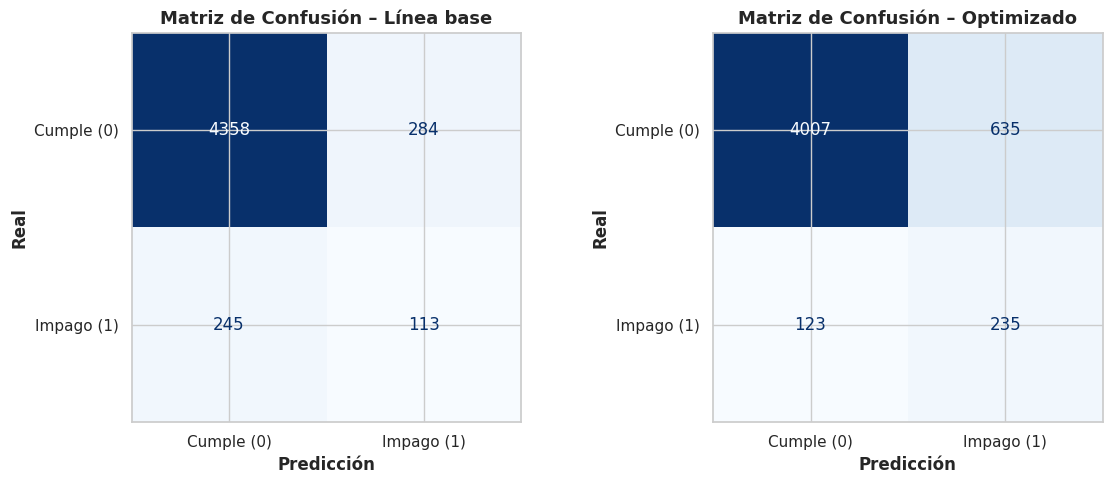

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, modelo) in zip(axes, [("Línea base", modelo_base), ("Optimizado", modelo_opt)]):
    cm = confusion_matrix(y_test, modelo.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Cumple (0)", "Impago (1)"]).plot(
        ax=ax, cmap=plt.cm.Blues, values_format="d", colorbar=False)
    ax.set_title(f"Matriz de Confusión – {nombre}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicción", fontweight="bold"); ax.set_ylabel("Real", fontweight="bold")
plt.tight_layout(); plt.show()

**Cómo leer la matriz en este negocio** (clase positiva = impago):

| | Predice "Cumple" (se otorga el crédito) | Predice "Impago" (se deniega) |
|---|---|---|
| **Real: Cumple** | **VN** – crédito bueno otorgado ✅ | **FP** – crédito bueno rechazado ❌ pierde intereses ($200.000 c/u) |
| **Real: Impago** | **FN** – crédito  malo otorgado ❌ pérdida  de       capital ($1.500.000 c/u) | **VP** – impago evitado ✅ |

### Interpretación – Modelo Línea Base

In [56]:
from IPython.display import Markdown, display
def clp(x):  return "\\$" + f"{x:,.0f}".replace(",", ".")          # \$1.500.000
def num(x):  return f"{int(x):,}".replace(",", ".")
def dec(x, d=3): return f"{x:.{d}f}".replace(".", ",")
def pct(x, d=1): return f"{x*100:.{d}f}".replace(".", ",") + " %"

b, o = resultados.loc["Línea base"], resultados.loc["Optimizado"]
n_test, n_imp = len(y_test), int(b["FN"] + b["VP"])
recall_train_base = recall_score(y_train, modelo_base.predict(X_train))
c_todos = n_imp * COSTO_FN

display(Markdown(f"""
*(Cifras del conjunto de prueba de {num(n_test)} clientes, de los cuales {num(n_imp)} son impagos reales; `random_state = 29`)*

- **Verdadero Negativo = {num(b["VN"])}:** clientes cumplidores a los que se les concede el crédito correctamente.
- **Verdadero Positivo = {num(b["VP"])}:** impagos detectados y evitados.
- **Falso Negativo = {num(b["FN"])}:** clientes que **caerían en impago pero el modelo aprueba**. Es el error más grave: {num(b["FN"])} × {clp(COSTO_FN)} = **{clp(b["Costo FN ($)"])}** de pérdida directa de capital. El modelo solo detecta {pct(b["Recall (impago)"])} de los impagos (recall = {dec(b["Recall (impago)"])}): **deja pasar ~{round((1-b["Recall (impago)"])*10)} de cada 10 clientes riesgosos**.
- **Falso Positivo = {num(b["FP"])}:** clientes buenos rechazados, con un costo de oportunidad de {num(b["FP"])} × {clp(COSTO_FP)} = **{clp(b["Costo FP ($)"])}**.
- **Costo total ≈ {clp(b["Costo total ($)"])}.**
- **Precision = {dec(b["Precision (impago)"])}:** de cada 100 clientes que el modelo marca como riesgosos, solo ~{round(b["Precision (impago)"]*100)} realmente caerían en impago.

**Frente a no usar modelo:** aprobar a todos costaría {clp(c_todos)}; la línea base solo reduce ese costo en {pct(1 - b["Costo total ($)"]/c_todos, 1)}, un aporte modesto.

La *accuracy* de {pct(b["Accuracy [referencia]"])} parece buena, pero es engañosa: el modelo se ve bien porque la clase mayoritaria es abrumadora, mientras que falla en lo que realmente importa. Es coherente con el **sobreajuste** observado: con un recall de {dec(recall_train_base)} en entrenamiento y {dec(b["Recall (impago)"])} en prueba, el árbol sin restricciones memorizó el entrenamiento y no generaliza.
"""))


*(Cifras del conjunto de prueba de 5.000 clientes, de los cuales 358 son impagos reales; `random_state = 29`)*

- **Verdadero Negativo = 4.358:** clientes cumplidores a los que se les concede el crédito correctamente.
- **Verdadero Positivo = 113:** impagos detectados y evitados.
- **Falso Negativo = 245:** clientes que **caerían en impago pero el modelo aprueba**. Es el error más grave: 245 × \$1.500.000 = **\$367.500.000** de pérdida directa de capital. El modelo solo detecta 31,6 % de los impagos (recall = 0,316): **deja pasar ~7 de cada 10 clientes riesgosos**.
- **Falso Positivo = 284:** clientes buenos rechazados, con un costo de oportunidad de 284 × \$200.000 = **\$56.800.000**.
- **Costo total ≈ \$424.300.000.**
- **Precision = 0,285:** de cada 100 clientes que el modelo marca como riesgosos, solo ~28 realmente caerían en impago.

**Frente a no usar modelo:** aprobar a todos costaría \$537.000.000; la línea base solo reduce ese costo en 21,0 %, un aporte modesto.

La *accuracy* de 89,4 % parece buena, pero es engañosa: el modelo se ve bien porque la clase mayoritaria es abrumadora, mientras que falla en lo que realmente importa. Es coherente con el **sobreajuste** observado: con un recall de 1,000 en entrenamiento y 0,316 en prueba, el árbol sin restricciones memorizó el entrenamiento y no generaliza.


### Interpretación – Modelo Optimizado y comparación

In [57]:
d_vp, d_fn, d_fp = int(o["VP"]-b["VP"]), int(b["FN"]-o["FN"]), int(o["FP"]-b["FP"])
ahorro = b["Costo total ($)"] - o["Costo total ($)"]
display(Markdown(f"""
- **Verdadero Positivo = {num(o["VP"])}** (antes {num(b["VP"])}): se detectan {num(d_vp)} impagos más; el recall sube de {dec(b["Recall (impago)"])} a **{dec(o["Recall (impago)"])}**.
- **Falso Negativo = {num(o["FN"])}** (antes {num(b["FN"])}): se evitan {num(d_fn)} créditos malos adicionales. Ahorro de {num(d_fn)} × {clp(COSTO_FN)} = **{clp(d_fn*COSTO_FN)}** en pérdidas de capital.
- **Falso Positivio = {num(o["FP"])}** (antes {num(b["FP"])}): el modelo rechaza {num(d_fp)} clientes buenos más. Es el precio de ser más conservador: {num(d_fp)} × {clp(COSTO_FP)} = **{clp(d_fp*COSTO_FP)}** adicionales en costo de oportunidad.
- **Precision = {dec(o["Precision (impago)"])}** (antes {dec(b["Precision (impago)"])}): de cada 100 clientes marcados como riesgosos, ~{round(o["Precision (impago)"]*100)} serían realmente impagos.
- **Costo total ≈ {clp(o["Costo total ($)"])}**, es decir, **{clp(ahorro)} menos ({pct(ahorro/b["Costo total ($)"])})** que la línea base y {pct(1 - o["Costo total ($)"]/c_todos)} menos que aprobar a todos.
- La *accuracy* baja ({pct(b["Accuracy [referencia]"])} → {pct(o["Accuracy [referencia]"])}). Esto **no es un empeoramiento**: es una decisión consciente de intercambiar algunos rechazos de clientes buenos por detectar muchos más impagos, lo cual conviene porque cada FN cuesta 7,5 veces más que un FP.

**Conclusión:** el modelo optimizado es claramente superior desde el punto de vista del negocio. Aun así, todavía no detecta ~{pct(1-o["Recall (impago)"], 0)} de los impagos y rechaza a {num(o["FP"])} clientes buenos, por lo que debe usarse como **herramienta de apoyo** a la decisión (por ejemplo, para priorizar revisión manual de las solicitudes marcadas como riesgosas), no como decisión automática. Los ahorros son estimaciones sobre {num(n_test)} clientes de prueba con los costos unitarios de estudios preliminares.
"""))


- **Verdadero Positivo = 235** (antes 113): se detectan 122 impagos más; el recall sube de 0,316 a **0,656**.
- **Falso Negativo = 123** (antes 245): se evitan 122 créditos malos adicionales. Ahorro de 122 × \$1.500.000 = **\$183.000.000** en pérdidas de capital.
- **Falso Positivio = 635** (antes 284): el modelo rechaza 351 clientes buenos más. Es el precio de ser más conservador: 351 × \$200.000 = **\$70.200.000** adicionales en costo de oportunidad.
- **Precision = 0,270** (antes 0,285): de cada 100 clientes marcados como riesgosos, ~27 serían realmente impagos.
- **Costo total ≈ \$311.500.000**, es decir, **\$112.800.000 menos (26,6 %)** que la línea base y 42,0 % menos que aprobar a todos.
- La *accuracy* baja (89,4 % → 84,8 %). Esto **no es un empeoramiento**: es una decisión consciente de intercambiar algunos rechazos de clientes buenos por detectar muchos más impagos, lo cual conviene porque cada FN cuesta 7,5 veces más que un FP.

**Conclusión:** el modelo optimizado es claramente superior desde el punto de vista del negocio. Aun así, todavía no detecta ~34 % de los impagos y rechaza a 635 clientes buenos, por lo que debe usarse como **herramienta de apoyo** a la decisión (por ejemplo, para priorizar revisión manual de las solicitudes marcadas como riesgosas), no como decisión automática. Los ahorros son estimaciones sobre 5.000 clientes de prueba con los costos unitarios de estudios preliminares.


In [52]:
# Resumen de la comparacion financiera (calculo automatico para verificar las cifras)
base, opt = resultados.loc["Línea base"], resultados.loc["Optimizado"]
ahorro = base["Costo total ($)"] - opt["Costo total ($)"]
print(f"Costo total línea base : ${base['Costo total ($)']:,.0f}")
print(f"Costo total optimizado : ${opt['Costo total ($)']:,.0f}")
print(f"Ahorro del optimizado  : ${ahorro:,.0f}  ({ahorro / base['Costo total ($)'] * 100:.1f}%)")
print(f"Impagos adicionales detectados: {int(opt['VP'] - base['VP'])}")
print(f"Clientes buenos adicionales rechazados: {int(opt['FP'] - base['FP'])}")

Costo total línea base : $424,300,000
Costo total optimizado : $311,500,000
Ahorro del optimizado  : $112,800,000  (26.6%)
Impagos adicionales detectados: 122
Clientes buenos adicionales rechazados: 351


## 4.3 Interpretación del árbol optimizado

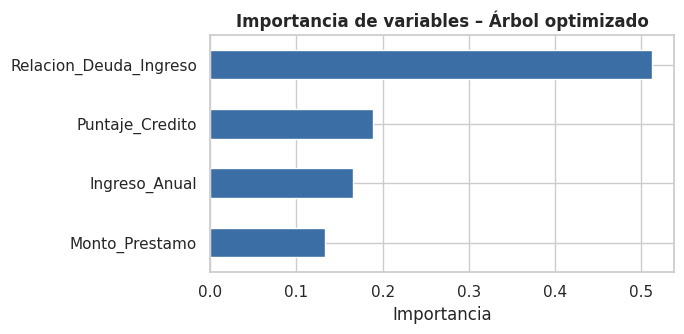

Relacion_Deuda_Ingreso    0.512
Puntaje_Credito           0.189
Ingreso_Anual             0.166
Monto_Prestamo            0.133
dtype: float64


In [53]:
# Importancia de las variables
imp = pd.Series(arbol_opt.feature_importances_, index=features).sort_values()
ax = imp.plot(kind="barh", figsize=(7, 3.5), color="#3B6EA5")
ax.set_title("Importancia de variables – Árbol optimizado", fontweight="bold")
ax.set_xlabel("Importancia")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(3))

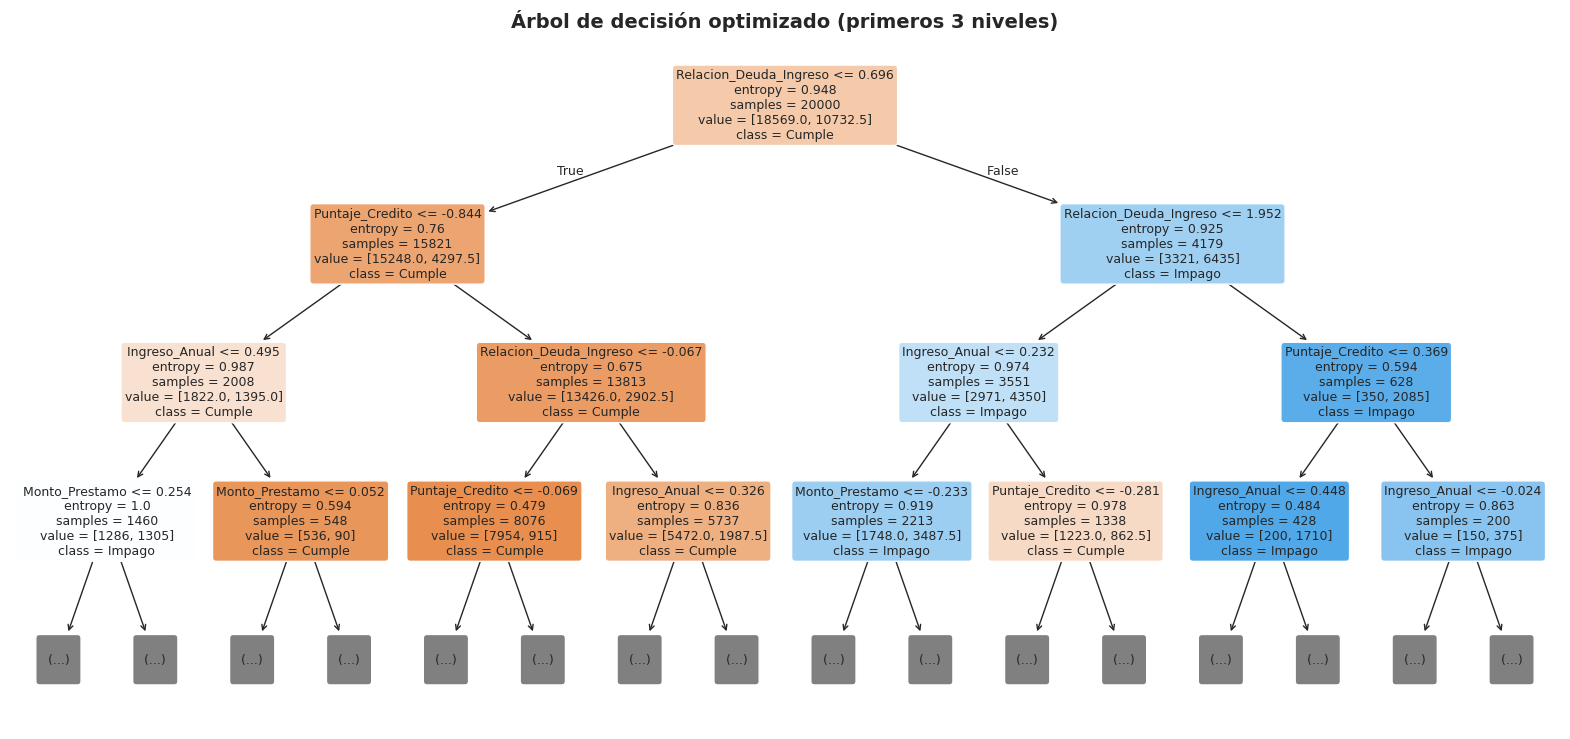

In [54]:
# Visualizacion de los primeros niveles del arbol optimizado
plt.figure(figsize=(20, 9))
plot_tree(arbol_opt, feature_names=features, class_names=["Cumple", "Impago"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Árbol de decisión optimizado (primeros 3 niveles)", fontsize=14, fontweight="bold")
plt.show()

In [55]:
imp_ord = imp.sort_values(ascending=False)
top1, top2 = imp_ord.index[0], imp_ord.index[1]
display(Markdown(f"""
Las variables con mayor peso en el modelo son las que mejor separan a cumplidores de impagos: `{top1}` ≈ {imp_ord.iloc[0]*100:.0f} % de la importancia, seguida de `{top2}` ≈ {imp_ord.iloc[1]*100:.0f} % (ver gráfico). Esto es coherente con el criterio financiero: **más deuda respecto del ingreso y menor historial crediticio implican mayor riesgo de impago**. Las reglas del árbol son explicables, ventaja importante en un entorno regulado.
"""))


Las variables con mayor peso en el modelo son las que mejor separan a cumplidores de impagos: `Relacion_Deuda_Ingreso` ≈ 51 % de la importancia, seguida de `Puntaje_Credito` ≈ 19 % (ver gráfico). Esto es coherente con el criterio financiero: **más deuda respecto del ingreso y menor historial crediticio implican mayor riesgo de impago**. Las reglas del árbol son explicables, ventaja importante en un entorno regulado.
